# Main pipeline:
# * Fully-connected Autoencoder + simple classifiers
# * Fully-connected Autoencoder + LSTM
# * Convolutional autoencoder + LSTM
# * Raw channels + LSTM  

Builds a 10-minute pre-arrival window per patient,
encodes each 30-second interval's 11 channels.

**Prediction tasks:** arrival lactate (regression), mortality (classification), amount of blood transfusion (classification).




## 1. Data preprocessing

### a) Config & channel set

In [ ]:
import os, re, zipfile
import numpy as np, pandas as pd
import torch, torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt

SUMMARY_CSV  = "summary.csv"
ZIP_PATH     = "CSVFiles.zip"
ID_COL       = "Filename"
TIME_COL     = "datetime"
OUTCOME_PATH = "Deidentified_EPCR_ZOLL_London_Trauma_ZOLL_03_04.xlsx"
OUTCOME_ID   = "Deidentified_JSON_ZOLL_x"
OUTPUT_DIR   = "outputs"; os.makedirs(OUTPUT_DIR, exist_ok=True)

WINDOW_MIN = 10
BIN_SEC    = 30
T          = WINDOW_MIN * 60 // BIN_SEC         # 20 intervals
ANCHOR     = "Hr"

CHANNELS = ["Hr", "Spo2", "Nibp_sys", "Nibp_dia", "Nibp_mean", "Ibp_sys", "Ibp_dia", "Ibp_map", "Etco2", "Resp", "SpPI"]
MEASURES = {
    "Hr":       {"token": "hr",   "value_col": "HR_value",        "vmin": 20, "vmax": 220},
    "Spo2":     {"token": "spo2", "value_col": "Spo2_value",      "vmin": 40, "vmax": 100},
    "Nibp_sys": {"token": "nibp", "value_col": "Nibp_Sys_value",  "vmin": 50, "vmax": 250},
    "Nibp_dia": {"token": "nibp", "value_col": "Nibp_Dia_value",  "vmin": 20, "vmax": 150},
    "Nibp_mean":{"token": "nibp", "value_col": "Nibp_mean_value", "vmin": 30, "vmax": 180},
    "Ibp_sys":   {"token": "ibp", "value_col": "ibp0_Sys_value", "vmin": 50, "vmax": 250},
    "Ibp_dia":   {"token": "ibp",  "value_col": "ibp0_Dia_value", "vmin": 20, "vmax": 150},
    "Ibp_map":   {"token": "ibp",  "value_col": "ibp0_Mean_value",  "vmin": 30, "vmax": 180},
    "Etco2":    {"token": "etco2","value_col": "Etco2_value",     "vmin": 5,  "vmax": 80},
    "Resp":     {"token": "resp", "value_col": "Resp_value",      "vmin": 3,  "vmax": 60},
    "SpPI": {"token": "sppi", "value_col": "PI_value",  "vmin": 0,  "vmax": 100}
}
C = len(CHANNELS)
LATENT_SWEEP = [2,3,4,5,6,7,8,9,10]

df = pd.read_csv(SUMMARY_CSV); df.columns = [c.strip() for c in df.columns]
zf = zipfile.ZipFile(ZIP_PATH); names = set(zf.namelist())
print("recordings in summary:", len(df))

recordings in summary: 606


### b) (bin & aggregate)

Per patient: anchor on the last valid HR reading, take the 10 minutes ending there, and for
every channel bin its valid-and-nonzero readings into the 30-second intervals,
aggregating by mean. Produces two aligned arrays per patient — data (20×11) and mask
(20×11, 1 = a real reading present). Patients without a full 10-minute HR window are dropped.

In [ ]:
# find the right per-channel csv in the zip for a given recording ID
def detail_name(fn, token):
    fnl = str(fn).lower()
    for n in names:
        b = n.lower()
        if fnl in b and b.endswith(".csv") and re.search(rf"(^|[_/]){token}([_.])", b):
            return n
    return None

# load one channel's raw csv for one patient
def load_channel(fn, cfg):
    """valid-and-nonzero, in-range, de-duplicated readings: DataFrame[t, val]."""
    name = detail_name(fn, cfg["token"])
    if name is None:
        return None
    with zf.open(name) as f:
        d = pd.read_csv(f)
    d.columns = [c.strip() for c in d.columns]
    vcol = cfg["value_col"]

    vpos = d.columns.get_loc(vcol)
    if vpos == 0 or TIME_COL not in d.columns:
        return None
    scol = d.columns[vpos - 1]     # status column = one to the left of value column

    # parse the time column into actual datetime object
    t   = pd.to_datetime(d[TIME_COL], errors="coerce")
    val = pd.to_numeric(d[vcol], errors="coerce") / cfg.get("scale", 1)
    valid = d[scol].astype(str).str.strip().str.lower().eq("valid")

    # choose valid, in range, non-zero, deduplicated readings
    o = pd.DataFrame({"t": t, "val": val, "valid": valid}).dropna(subset=["t"])
    good = o["valid"] & (o["val"] != 0) & o["val"].between(cfg["vmin"], cfg["vmax"])
    return o[good].drop_duplicates(subset=["t", "val"]).sort_values("t")

# load hr series to anchor the time period
def build_window(fn):
    hr = load_channel(fn, MEASURES[ANCHOR])
    if hr is None or len(hr) == 0:
        return None
    t_end   = hr["t"].max()
    t_start = t_end - pd.Timedelta(seconds=WINDOW_MIN * 60)
    if hr["t"].min() > t_start:                 # require a full 10-min HR span
        return None
    # 2 output arrays for each patient ( 10 internals x 11 channels)
    data = np.zeros((T, C), dtype="float32")
    mask = np.zeros((T, C), dtype="float32")

    # loops over the 11 channels
    for ci, ch in enumerate(CHANNELS):
        s = hr if ch == ANCHOR else load_channel(fn, MEASURES[ch])
        if s is None or len(s) == 0:
            continue                             # channel absent -> stays masked

        # how many seconds before t_end each readings occurred
        sb = (t_end - s["t"]).dt.total_seconds().to_numpy()
        inwin = (sb >= 0) & (sb < WINDOW_MIN * 60)
        sb, vv = sb[inwin], s["val"].to_numpy()[inwin]
        if len(vv) == 0:
            continue
        # create a bin index
        b = (T - 1 - (sb // BIN_SEC)).astype(int)

        # aggreagate to the mean, add mask
        for bi in np.unique(b):
            data[bi, ci] = vv[b == bi].mean()
            mask[bi, ci] = 1.0
    return data, mask

In [ ]:
# create 2D arrays Xs and Ms of shape (20,11), where Xs stores the measures and Ms the mask
Xs, Ms, ids = [], [], []
for fn in df[ID_COL]:
    r = build_window(fn)
    if r is not None:
        Xs.append(r[0]); Ms.append(r[1]); ids.append(fn)

# create a 3D tensor of shape (n_patients, 20, 11), where a 20 x 11 table is stored for every patient
X = np.stack(Xs); M = np.stack(Ms); ids = np.array(ids)
print(f"kept {len(ids)} of {len(df)} patients | X shape {X.shape} (patients, intervals, channels)")

# compute a fraction of all cells that have an actual reading (mask = 1)
print("per-channel % intervals observed:")
for ci, ch in enumerate(CHANNELS):
    print(f"  {ch:10s}: {M[:,:,ci].mean()*100:5.1f}%")

kept 603 of 606 patients | X shape (603, 20, 11) (patients, intervals, channels)
per-channel % intervals observed:
  Hr        :  92.7%
  Spo2      :  72.7%
  Nibp_sys  :  40.0%
  Nibp_dia  :  39.9%
  Nibp_mean :  39.8%
  Ibp_sys   :  19.2%
  Ibp_dia   :  19.5%
  Ibp_map   :  19.5%
  Etco2     :  52.8%
  Resp      :  67.6%
  SpPI      :  40.4%


### c) Split & normalise

Patient-level 70/15/15 split. Per-channel standardisation using training valid values only;
missing entries stay 0 and are kept out via the mask.

In [ ]:
idx = np.arange(len(ids))
tr, tmp = train_test_split(idx, test_size=0.30, random_state=42)
va, te  = train_test_split(tmp, test_size=0.50, random_state=42)

# for each channel gather only observed (mask=1) training values and compute their 95 percentile to use it as per channel scale factor
scale = np.ones(C)
percentile = 95
for ci in range(C):
    vals = X[tr][:, :, ci][M[tr][:, :, ci] > 0]
    if len(vals):
        scale[ci] = np.percentile(vals, percentile) + 1e-6

Xn = (X / scale) * M   # missing values remain exactly zero

print("train/val/test patients:", len(tr), len(va), len(te))

train/val/test patients: 422 90 91



## 2. Fully-connected autoencoder


### a) Latent sweep
Encodes one interval's 11-channel vector to k latent dims and reconstructs it, with the loss
computed only over observed channels (masked). Trained on all intervals of the training
patients (each interval is one sample).

latent 2: masked val MSE 0.01499
latent 3: masked val MSE 0.01023
latent 4: masked val MSE 0.00808
latent 5: masked val MSE 0.00544
latent 6: masked val MSE 0.00311
latent 7: masked val MSE 0.00179
latent 8: masked val MSE 0.00100
latent 9: masked val MSE 0.00088
latent 10: masked val MSE 0.00082


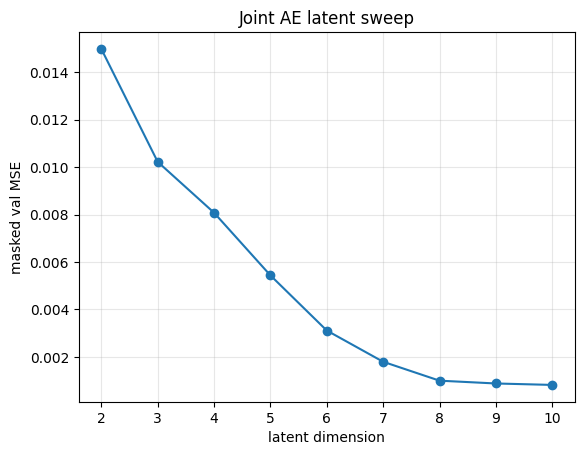

In [ ]:

def to_t(a): return torch.tensor(a, dtype=torch.float32)

# custom masked loss function
def masked_mse(recon, x, m): return ((recon - x) ** 2 * m).sum() / (m.sum() + 1e-8)

class IntervalAE(nn.Module):
    def __init__(self, C, latent):
        super().__init__()
        # compress the 11-channel vector down to a small bottleneck
        self.enc = nn.Sequential(nn.Linear(C, 16), nn.ReLU(), nn.Linear(16, latent))
        # reconstruct the original 11-channel vector from bottleneck
        self.dec = nn.Sequential(nn.Linear(latent, 16), nn.ReLU(), nn.Linear(16, C))
    # return the reconstruction and the latent code (what would further feed into the model)
    def forward(self, x):
        z = self.enc(x); return self.dec(z), z

# reshapes the training and validation data from (n_patients, 20, 11) to (n_patients * 20, 11)
def train_ae(latent, epochs=120, lr=1e-3, batch=256, seed=42):
    torch.manual_seed(seed)
    Xtr, Mtr = to_t(Xn[tr].reshape(-1, C)), to_t(M[tr].reshape(-1, C))
    Xva, Mva = to_t(Xn[va].reshape(-1, C)), to_t(M[va].reshape(-1, C))

    # Standard PyTorch training loop
    model = IntervalAE(C, latent); opt = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(epochs):
        model.train()
        for b in torch.randperm(len(Xtr)).split(batch):
            opt.zero_grad()
            recon, _ = model(Xtr[b]); loss = masked_mse(recon, Xtr[b], Mtr[b])
            loss.backward(); opt.step()

    # masked MSE on the held-out validation set
    model.eval()
    with torch.no_grad():
        vl = masked_mse(model(Xva)[0], Xva, Mva).item()
    return model, vl

# train a separate autoencoder on every dimension
ae = {}
for k in LATENT_SWEEP:
    m, vl = train_ae(k); ae[k] = {"model": m, "val": vl}
    print(f"latent {k}: masked val MSE {vl:.5f}")

plt.plot(list(ae), [ae[k]["val"] for k in ae], "o-")
plt.xlabel("latent dimension"); plt.ylabel("masked val MSE"); plt.title("Joint AE latent sweep")
plt.grid(alpha=.3); plt.show()

### b) 6-seed latent sweep
For each candidate latent dimension k, the AE is trained six times from six different random initialisations, collecting the trained model and its masked validation MSE each time.

latent 2: masked val MSE 0.01623 +/- 0.00095
latent 3: masked val MSE 0.01121 +/- 0.00108
latent 4: masked val MSE 0.00665 +/- 0.00099
latent 5: masked val MSE 0.00448 +/- 0.00067
latent 6: masked val MSE 0.00358 +/- 0.00028
latent 7: masked val MSE 0.00245 +/- 0.00036
latent 8: masked val MSE 0.00218 +/- 0.00039
latent 9: masked val MSE 0.00126 +/- 0.00039
latent 10: masked val MSE 0.00094 +/- 0.00014


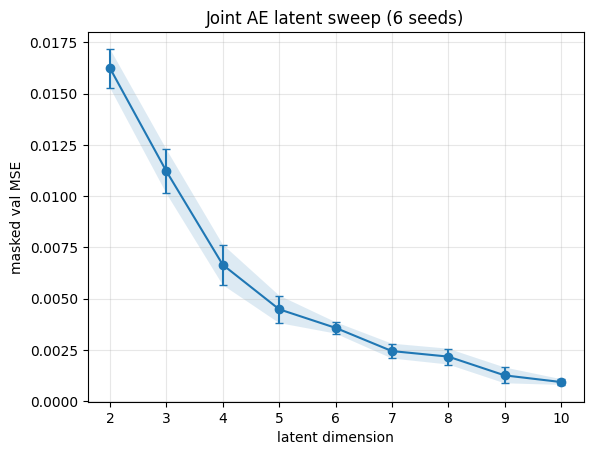

In [ ]:
SWEEP_SEEDS = range(6)

ae = {}
for k in LATENT_SWEEP:
    vals, models = [], []
    for s in SWEEP_SEEDS:
        m, vl = train_ae(k, seed=s)
        vals.append(vl); models.append(m)
    vals = np.array(vals)
    # keep the median-performing seed's model
    keep = int(np.argsort(vals)[len(vals) // 2])
    ae[k] = {"model": models[keep], "val": vals.mean(),
             "std": vals.std(), "all": vals}
    print(f"latent {k}: masked val MSE {vals.mean():.5f} +/- {vals.std():.5f}")

ks   = list(ae)
mean = np.array([ae[k]["val"] for k in ks])
sd   = np.array([ae[k]["std"] for k in ks])

plt.errorbar(ks, mean, yerr=sd, fmt="o-", capsize=3)
plt.fill_between(ks, mean - sd, mean + sd, alpha=.15)
plt.xlabel("latent dimension"); plt.ylabel("masked val MSE")
plt.title(f"Joint AE latent sweep ({len(SWEEP_SEEDS)} seeds)")
plt.grid(alpha=.3); plt.show()

### c) Autoencoder with the best performing latent dimensions

In [ ]:
BEST_LATENT = 9
encoder = ae[BEST_LATENT]["model"]
encoder.eval()

with torch.no_grad():
    # encode each interval: (N, T, C) -> (N*T, C) -> encoder -> (N*T, 11) -> (N, T, 11)
    Zseq_dense = encoder.enc(to_t(Xn.reshape(-1, C))).numpy().reshape(len(ids), T, BEST_LATENT)

# flatten each patient's sequence of 20 latents into one feature vector: (N, T*11) = (N, 180)
Zflat = Zseq_dense.reshape(len(ids), T * BEST_LATENT)
print("per-patient feature matrix:", Zflat.shape)

# load labels and align them with patient records
outc = pd.read_excel(OUTCOME_PATH); outc.columns = [c.strip() for c in outc.columns]
lab  = outc.set_index(OUTCOME_ID)

def get_label(column):
    return pd.to_numeric(pd.Series(ids).map(lab[column]), errors="coerce").to_numpy()

print("label join match: %.1f%%" % (pd.Series(ids).isin(lab.index).mean() * 100))

per-patient feature matrix: (603, 180)
label join match: 100.0%


### d) AE + Linear Regression for a continuous target (lactate)

In [ ]:
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, r2_score, roc_auc_score

def linear_regression_task(target):
    y = get_label(target)
    keep = lambda s: np.array([i for i in s if not np.isnan(y[i])])
    trL, teL = keep(tr), keep(te)                       # labelled patients per split

    sc  = StandardScaler().fit(Zflat[trL])              # standardise features on train
    reg = LinearRegression().fit(sc.transform(Zflat[trL]), y[trL])
    pred = reg.predict(sc.transform(Zflat[teL]))

    mae  = mean_absolute_error(y[teL], pred)
    base = np.mean(np.abs(y[teL] - np.median(y[trL])))  # predict train median
    print(f"[{target}] test MAE {mae:.3f} | baseline {base:.3f} | "
          f"R2 {r2_score(y[teL], pred):.3f} | n_test {len(teL)}")

linear_regression_task("First lactate (hospital arrival)")

[First lactate (hospital arrival)] test MAE 5.574 | baseline 3.257 | R2 -3.004 | n_test 67


### e) AE + Logistic Regression for a binary target (mortality)

In [ ]:
def logistic_regression_task(target="Outcome Alive 0/Dead 1"):
    y = get_label(target)
    keep = lambda s: np.array([i for i in s if not np.isnan(y[i])])
    trL, teL = keep(tr), keep(te)

    sc  = StandardScaler().fit(Zflat[trL])
    clf = LogisticRegression(max_iter=1000).fit(sc.transform(Zflat[trL]), y[trL])
    p   = clf.predict_proba(sc.transform(Zflat[teL]))[:, 1]
    print(f"[{target}] test AUROC {roc_auc_score(y[teL], p):.3f} | n_test {len(teL)}")

logistic_regression_task("Outcome Alive 0/Dead 1")

[Outcome Alive 0/Dead 1] test AUROC 0.646 | n_test 84


### f) AE + Random forest regression for continuous target (lactate)

In [ ]:
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
def random_forest_regression(target, n_estimators=300, seed=42):
    y = get_label(target)
    keep = lambda s: np.array([i for i in s if not np.isnan(y[i])])
    trL, teL = keep(tr), keep(te)

    rf   = RandomForestRegressor(n_estimators=n_estimators, random_state=seed)
    rf.fit(Zflat[trL], y[trL])
    pred = rf.predict(Zflat[teL])

    mae  = mean_absolute_error(y[teL], pred)
    base = np.mean(np.abs(y[teL] - np.median(y[trL])))
    print(f"[RF {target}] test MAE {mae:.3f} | baseline {base:.3f} | "
          f"R2 {r2_score(y[teL], pred):.3f} | n_test {len(teL)}")

random_forest_regression("First lactate (hospital arrival)")


[RF First lactate (hospital arrival)] test MAE 3.201 | baseline 3.257 | R2 0.043 | n_test 67


### g) AE + Random forest classification for binary target (mortality)

In [ ]:
def random_forest_classification(target="Outcome Alive 0/Dead 1", n_estimators=300, seed=42):
    y = get_label(target)
    keep = lambda s: np.array([i for i in s if not np.isnan(y[i])])
    trL, teL = keep(tr), keep(te)

    rf = RandomForestClassifier(n_estimators=n_estimators, random_state=seed,
                                class_weight="balanced")   # handles mortality imbalance
    rf.fit(Zflat[trL], y[trL])
    p  = rf.predict_proba(Zflat[teL])[:, 1]
    print(f"[RF {target}] test AUROC {roc_auc_score(y[teL], p):.3f} | n_test {len(teL)}")

random_forest_classification("Outcome Alive 0/Dead 1")

[RF Outcome Alive 0/Dead 1] test AUROC 0.766 | n_test 84


In [ ]:
# mask flattened per patient (presence pattern only)
Mflat = M.reshape(len(ids), -1)                 # (N, T*C)

# three feature sets to compare for mortality
feature_sets = {
    "latents only (current)":   Zflat,
    "presence (mask) only":     Mflat,
    "latents + mask":           np.concatenate([Zflat, Mflat], axis=1),
}

y = get_label("Outcome Alive 0/Dead 1")
keep = lambda s: np.array([i for i in s if not np.isnan(y[i])])
trL, teL = keep(tr), keep(te)

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
for name, Xf in feature_sets.items():
    sc  = StandardScaler().fit(Xf[trL])
    clf = LogisticRegression(max_iter=1000).fit(sc.transform(Xf[trL]), y[trL])
    p   = clf.predict_proba(sc.transform(Xf[teL]))[:, 1]
    print(f"{name:24s}: test AUROC {roc_auc_score(y[teL], p):.3f}")

latents only (current)  : test AUROC 0.646
presence (mask) only    : test AUROC 0.593
latents + mask          : test AUROC 0.627


### h) AE + Random Forrest Classification for "24hr Prehospital + Hospital Blood Transfusion"

#### h.1) 3-class problem

In [ ]:
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, classification_report

TARGET_COL = "24hr Prehospital + Hospital Blood Transfusion"
raw = get_label(TARGET_COL)

def to_bands(v):
    if np.isnan(v):      return np.nan
    if v == 0:           return 0               # none
    if v < 10:           return 1               # moderate (1-9 units)
    return 2                                    # massive (>=10 units)

y = np.array([to_bands(v) for v in raw])
print("class counts:", {c: int((y == c).sum()) for c in [0, 1, 2] if not np.isnan(c)})

# random forest classification on the latent features
keep = lambda s: np.array([i for i in s if not np.isnan(y[i])])
trL, teL = keep(tr), keep(te)

rf = RandomForestClassifier(n_estimators=300, random_state=42, class_weight="balanced")
rf.fit(Zflat[trL], y[trL])
pred  = rf.predict(Zflat[teL])
proba = rf.predict_proba(Zflat[teL])

print(classification_report(y[teL], pred, digits=3))

# multi-class AUROC (one-vs-rest, averaged)
try:
    auc = roc_auc_score(y[teL], proba, multi_class="ovr", average="macro")
    print(f"macro one-vs-rest AUROC: {auc:.3f}")
except ValueError as e:
    print("AUROC skipped:", e)

class counts: {0: 125, 1: 369, 2: 108}
              precision    recall  f1-score   support

         0.0      0.333     0.056     0.095        18
         1.0      0.607     0.927     0.734        55
         2.0      0.500     0.111     0.182        18

    accuracy                          0.593        91
   macro avg      0.480     0.365     0.337        91
weighted avg      0.532     0.593     0.498        91

macro one-vs-rest AUROC: 0.607


In [ ]:
pd.to_numeric(pd.Series(get_label("24hr Prehospital + Hospital Blood Transfusion")), errors="coerce").describe()

,0
count,602.000000
mean,6.273256
std,10.208133
min,0.000000
25%,1.000000
50%,2.000000
75%,7.000000
max,77.000000


#### h.2) 2-class problem

In [ ]:
raw = pd.to_numeric(pd.Series(get_label("24hr Prehospital + Hospital Blood Transfusion")),
                    errors="coerce").to_numpy()
y = np.where(np.isnan(raw), np.nan, (raw >= 10).astype(float))   # 1 = massive (>=10 units)

print("massive:", int(np.nansum(y)), " / non-massive:", int((y == 0).sum()))

# random forest classification on the latent features
keep = lambda s: np.array([i for i in s if not np.isnan(y[i])])
trL, teL = keep(tr), keep(te)

rf = RandomForestClassifier(n_estimators=300, random_state=42, class_weight="balanced")
rf.fit(Zflat[trL], y[trL])
pred  = rf.predict(Zflat[teL])
proba = rf.predict_proba(Zflat[teL])

print(classification_report(y[teL], pred, digits=3))

massive: 108  / non-massive: 494
              precision    recall  f1-score   support

         0.0      0.807     0.973     0.882        73
         1.0      0.333     0.056     0.095        18

    accuracy                          0.791        91
   macro avg      0.570     0.514     0.489        91
weighted avg      0.713     0.791     0.726        91



In [ ]:
proba = rf.predict_proba(Zflat[teL])[:, 1]
print("massive-transfusion test AUROC:", roc_auc_score(y[teL], proba))

massive-transfusion test AUROC: 0.6259512937595131


#### h.3) testing the classification with a lower AUROC threshhold to prevent the model from being overly cautious to choose the "massive class"

In [ ]:
from sklearn.metrics import roc_auc_score, precision_recall_fscore_support

# robustly get P(massive) whether or not both classes are present
proba = rf.predict_proba(Zflat[teL])
if proba.shape[1] == 1:
    # model saw only one class in training — degenerate
    print("WARNING: model trained on a single class:", rf.classes_)
    p_te = np.full(len(teL), float(rf.classes_[0]))   # constant
else:
    massive_col = list(rf.classes_).index(1.0)        # find the column for class "massive"
    p_te = proba[:, massive_col]

print(f"test AUROC: {roc_auc_score(y[teL], p_te):.3f}\n")

for t in [0.50, 0.40, 0.30, 0.25, 0.20, 0.15, 0.10]:
    pred_t = (p_te >= t).astype(int)
    pr, rc, f1, _ = precision_recall_fscore_support(y[teL], pred_t, labels=[1], zero_division=0)
    tp = int(((pred_t == 1) & (y[teL] == 1)).sum())
    fp = int(((pred_t == 1) & (y[teL] == 0)).sum())
    print(f"t={t:.2f}  precision {pr[0]:.3f}  recall {rc[0]:.3f}  f1 {f1[0]:.3f}  "
          f"(caught {tp}/{int(y[teL].sum())} massive, {fp} false alarms)")

test AUROC: 0.626

t=0.50  precision 0.333  recall 0.056  f1 0.095  (caught 1/18 massive, 2 false alarms)
t=0.40  precision 0.333  recall 0.111  f1 0.167  (caught 2/18 massive, 4 false alarms)
t=0.30  precision 0.214  recall 0.167  f1 0.188  (caught 3/18 massive, 11 false alarms)
t=0.25  precision 0.238  recall 0.278  f1 0.256  (caught 5/18 massive, 16 false alarms)
t=0.20  precision 0.286  recall 0.444  f1 0.348  (caught 8/18 massive, 20 false alarms)
t=0.15  precision 0.289  recall 0.722  f1 0.413  (caught 13/18 massive, 32 false alarms)
t=0.10  precision 0.246  recall 0.889  f1 0.386  (caught 16/18 massive, 49 false alarms)


### i) AE + Random Forrest Classification for "24hr blood products"

In [ ]:
# create new binary target
raw = pd.to_numeric(pd.Series(get_label("24hr blood products")), errors="coerce").to_numpy()
y = np.where(np.isnan(raw), np.nan, (raw >= 1).astype(float))   # 1 = any hospital transfusion

n_pos = int(np.nansum(y)); n_neg = int((y == 0).sum())
print(f"any hospital transfusion: {n_pos}  |  none: {n_neg}")

# keep only labelled patients in each split
keep = lambda s: np.array([i for i in s if not np.isnan(y[i])])
trL, teL = keep(tr), keep(te)

# fit the random forest on the training patients
rf = RandomForestClassifier(n_estimators=300, random_state=42, class_weight="balanced")
rf.fit(Zflat[trL], y[trL])

# predicted probability of the positive class
proba = rf.predict_proba(Zflat[teL])
pos_col = list(rf.classes_).index(1.0)     # find the column for class "1"
p_te = proba[:, pos_col]

# AUROC: the threshold-independent signal check
print(f"test AUROC: {roc_auc_score(y[teL], p_te):.3f}\n")


any hospital transfusion: 201  |  none: 389
test AUROC: 0.560



In [ ]:
# threshold sweep: precision/recall trade-off for the positive class
n_total_pos = int(y[teL].sum())
for t in [0.50, 0.40, 0.30, 0.25, 0.20, 0.15, 0.10]:
    pred_t = (p_te >= t).astype(int)
    pr, rc, f1, _ = precision_recall_fscore_support(y[teL], pred_t, labels=[1], zero_division=0)
    tp = int(((pred_t == 1) & (y[teL] == 1)).sum())
    fp = int(((pred_t == 1) & (y[teL] == 0)).sum())
    print(f"t={t:.2f}  precision {pr[0]:.3f}  recall {rc[0]:.3f}  f1 {f1[0]:.3f}  "
          f"(caught {tp}/{n_total_pos}, {fp} false alarms)")

t=0.50  precision 0.400  recall 0.114  f1 0.178  (caught 4/35, 6 false alarms)
t=0.40  precision 0.407  recall 0.314  f1 0.355  (caught 11/35, 16 false alarms)
t=0.30  precision 0.451  recall 0.657  f1 0.535  (caught 23/35, 28 false alarms)
t=0.25  precision 0.420  recall 0.829  f1 0.558  (caught 29/35, 40 false alarms)
t=0.20  precision 0.403  recall 0.886  f1 0.554  (caught 31/35, 46 false alarms)
t=0.15  precision 0.395  recall 0.971  f1 0.562  (caught 34/35, 52 false alarms)
t=0.10  precision 0.393  recall 1.000  f1 0.565  (caught 35/35, 54 false alarms)


## 2. AE + LSTM with the best performing variables from the previous task ("24hr Prehospital + Hospital Blood Transfusion" and "mortality")

In [ ]:
# flatten data from (603, 20, 11) to (603x20, 11) -> every interval is a separate row
# run every row through the encoder to get latents
# fold back into (603, 20,11)
with torch.no_grad():
    Zseq_dense = ae[BEST_LATENT]["model"].enc(to_t(Xn.reshape(-1, C))).numpy().reshape(len(ids), T, BEST_LATENT)

In [ ]:
import torch, torch.nn as nn
from sklearn.metrics import roc_auc_score

# the three input representations for the ablation
Mseq = M                                   # (N, T, C) per-interval presence pattern
inputs = {
    "latents only (physiology)": Zseq_dense,                                  # (N, T, latent)
    "presence (mask) only":      Mseq,                                  # (N, T, C)
    "latents + mask":            np.concatenate([Zseq_dense, Mseq], axis=2),  # (N, T, latent+C)
}

# build the targets "mortality" and "transfusion"
def make_target(task):
    if task == "mortality":
        return pd.to_numeric(pd.Series(get_label("Outcome Alive 0/Dead 1")),
                             errors="coerce").to_numpy()
    if task == "transfusion":                       # massive vs not (>=10 units, combined)
        raw = pd.to_numeric(pd.Series(get_label("24hr Prehospital + Hospital Blood Transfusion")),
                            errors="coerce").to_numpy()
        return np.where(np.isnan(raw), np.nan, (raw >= 10).astype(float))
    raise ValueError(task)

# define LSTM network
class LSTMClassifier(nn.Module):
    def __init__(self, in_dim, hidden=32):
        super().__init__()
        self.lstm = nn.LSTM(in_dim, hidden, batch_first=True)
        self.head = nn.Linear(hidden, 1)
    # define forward pass
    def forward(self, x):
        _, (h, _) = self.lstm(x)          # h[-1] = final hidden state of the sequence
        return self.head(h[-1])

# convert NumPy array into a PyTorch tensor
def to_t(a): return torch.tensor(a, dtype=torch.float32)

# train and evaluate one model; returns AUROC on the chosen evaluation split (validation or test)
def train_eval_lstm(Xin, y, seed, hidden=32, eval_split="test", epochs=200, lr=1e-3):
    torch.manual_seed(seed)
    # filter patients to those with a non-missing label
    keep = lambda s: np.array([i for i in s if not np.isnan(y[i])])
    trL = keep(tr)
    evalL = keep(va) if eval_split == "val" else keep(te)   # evaluate on validation or test
    # convert features to a tensor
    Xt = to_t(Xin); yt = to_t(np.nan_to_num(y).reshape(-1, 1))

    # create the model with input dimension Xin.shape[2], chosen hidden size, Adam optimizer and lossf (binary cross-entropy loss)
    model = LSTMClassifier(Xin.shape[2], hidden=hidden); opt = torch.optim.Adam(model.parameters(), lr=lr)
    lossf = nn.BCEWithLogitsLoss()
    for _ in range(epochs):
        model.train(); opt.zero_grad()
        loss = lossf(model(Xt[trL]), yt[trL]); loss.backward(); opt.step()
    model.eval()
    with torch.no_grad():
        p = model(Xt[evalL]).numpy().ravel()
    return roc_auc_score(y[evalL], p)

tuning = {}   # (encoder, task, input) -> {"hidden", "val", "test"}
ENCODER = "dense"

SEEDS = range(6)
HIDDEN_SIZES = [16, 32, 64]                 # candidate LSTM memory sizes
for task in ["mortality", "transfusion"]:
    y = make_target(task)
    n_pos = int(np.nansum(y)); n_lab = int((~np.isnan(y)).sum())
    print(f"\n===== {task}  (positives {n_pos} of {n_lab} labelled) =====")
    # for each of the ablation inputs, choose the hidden size on the VALIDATION set, then report on TEST
    for name, Xin in inputs.items():
        # average validation AUROC across seeds for each candidate hidden size
        val_scores = {}
        for hidden in HIDDEN_SIZES:
            val_aucs = np.array([train_eval_lstm(Xin, y, s, hidden=hidden, eval_split="val") for s in SEEDS])
            val_scores[hidden] = val_aucs.mean()
        # pick the hidden size with the best validation AUROC
        best_hidden = max(val_scores, key=val_scores.get)
        # report the TEST AUROC for the chosen hidden size (averaged across seeds)
        test_aucs = np.array([train_eval_lstm(Xin, y, s, hidden=best_hidden, eval_split="test") for s in SEEDS])
        tuning[(ENCODER, task, name)] = {"hidden": best_hidden,
                                         "val": val_scores[best_hidden],
                                         "test": test_aucs}
        print(f"  {name:26s}: best hidden={best_hidden:>2} (val {val_scores[best_hidden]:.3f}) "
              f"| test AUROC {test_aucs.mean():.3f} ± {test_aucs.std():.3f}")


===== mortality  (positives 90 of 559 labelled) =====
  latents only (physiology) : best hidden=64 (val 0.670) | test AUROC 0.810 ± 0.073
  presence (mask) only      : best hidden=64 (val 0.649) | test AUROC 0.718 ± 0.024
  latents + mask            : best hidden=32 (val 0.621) | test AUROC 0.778 ± 0.046

===== transfusion  (positives 108 of 602 labelled) =====
  latents only (physiology) : best hidden=16 (val 0.600) | test AUROC 0.666 ± 0.022
  presence (mask) only      : best hidden=16 (val 0.558) | test AUROC 0.662 ± 0.018
  latents + mask            : best hidden=16 (val 0.581) | test AUROC 0.691 ± 0.025


In [ ]:
# calibration helpers
# Refit the physiology-only mortality model at the hidden size chosen on the
# validation set (read from `tuning`), across the same six seeds used for AUROC.
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
import matplotlib.pyplot as plt


def lstm_test_probs(Xin, y, seed, hidden, epochs=200, lr=1e-3):
    """Train one LSTM and return (test probabilities, test labels)."""
    torch.manual_seed(seed)
    keep = lambda s: np.array([i for i in s if not np.isnan(y[i])])
    trL, teL = keep(tr), keep(te)
    # Convert to tensors
    Xt = to_t(Xin); yt = to_t(np.nan_to_num(y).reshape(-1, 1))
    # per time-step feature width
    model = LSTMClassifier(Xin.shape[2], hidden=hidden)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    # apply the sigmoid internally
    lossf = nn.BCEWithLogitsLoss()
    # full-batch gradient descent -> every epoch is a single forward/backward/step over all training patients at once.
    for _ in range(epochs):
        model.train(); opt.zero_grad()
        lossf(model(Xt[trL]), yt[trL]).backward(); opt.step()
    model.eval()
    with torch.no_grad():
        logits = model(Xt[teL]).numpy().ravel()
    return 1 / (1 + np.exp(-logits)), y[teL]


def calibrate(encoder, Xin, task="mortality", name="latents only (physiology)",
              n_bins=5, plot=True):
    """Brier score (mean +/- sd over seeds) and a seed-averaged reliability curve."""
    h = tuning[(encoder, task, name)]["hidden"]
    y = make_target(task)
    runs = [lstm_test_probs(Xin, y, s, h) for s in SEEDS]
    y_true = runs[0][1]

    # one brier score per seed
    briers = np.array([brier_score_loss(yt, p) for p, yt in runs])
    base_rate = y_true.mean()
    brier_baseline = brier_score_loss(y_true, np.full(len(y_true), base_rate))
    print(f"[{encoder}] {task} | hidden={h} (validation-selected)")
    print(f"  Brier (model):    {briers.mean():.3f} +/- {briers.std():.3f}  over {len(SEEDS)} seeds")
    print(f"  Brier (baseline): {brier_baseline:.3f}  (always predict base rate {base_rate:.2f})")
    better = (briers.mean() < brier_baseline)
    print(f"  => model is {'better' if better else 'NOT better'} than baseline\n")

    # reliability curve on seed-averaged probabilities (a single seed is very
    # noisy at this test-set size)
    p_mean = np.mean([p for p, _ in runs], axis=0)
    frac_pos, mean_pred = calibration_curve(y_true, p_mean, n_bins=n_bins,
                                            strategy="quantile")
    print("bin  mean_predicted_risk  actual_death_rate")
    for mp, fp in zip(mean_pred, frac_pos):
        print(f"     {mp:.2f}                 {fp:.2f}")

    if plot:
        plt.figure(figsize=(5, 5))
        plt.plot([0, 1], [0, 1], "k--", label="perfect calibration")
        for p, yt in runs:
            fp_s, mp_s = calibration_curve(yt, p, n_bins=n_bins, strategy="quantile")
            plt.plot(mp_s, fp_s, "-", color="tab:blue", alpha=.25, linewidth=1)
        plt.plot(mean_pred, frac_pos, "o-", color="tab:blue", label="seed-averaged")
        plt.xlabel("mean predicted risk"); plt.ylabel("actual death rate")
        plt.title(f"Calibration — {task}, {encoder} (hidden={h})")
        plt.legend(); plt.grid(alpha=.3); plt.show()

    return {"hidden": h, "brier": briers, "baseline": brier_baseline,
            "curve": (mean_pred, frac_pos)}


### a) reliability check with calibration

[dense] mortality | hidden=64 (validation-selected)
  Brier (model):    0.123 +/- 0.013  over 6 seeds
  Brier (baseline): 0.147  (always predict base rate 0.18)
  => model is better than baseline

bin  mean_predicted_risk  actual_death_rate
     0.02                 0.00
     0.04                 0.00
     0.08                 0.06
     0.17                 0.35
     0.36                 0.47


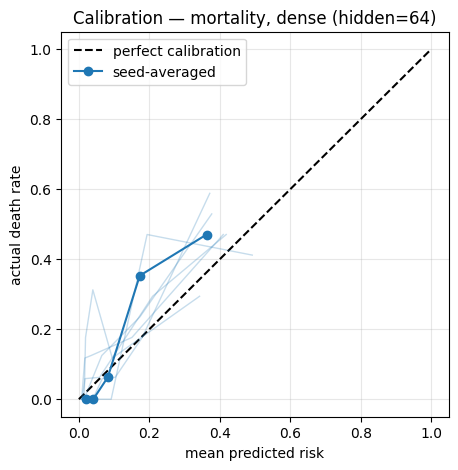

[dense] transfusion | hidden=16 (validation-selected)
  Brier (model):    0.153 +/- 0.003  over 6 seeds
  Brier (baseline): 0.159  (always predict base rate 0.20)
  => model is better than baseline

bin  mean_predicted_risk  actual_death_rate
     0.10                 0.04
     0.13                 0.22
     0.19                 0.27
     0.30                 0.26


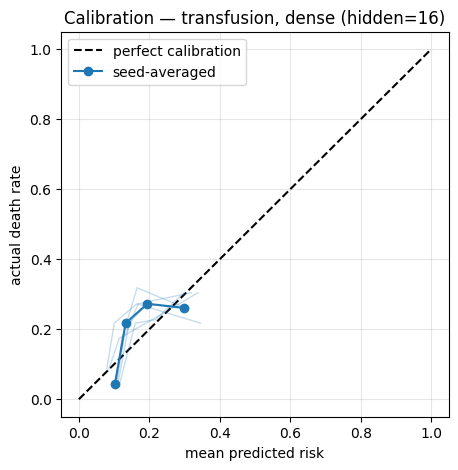

In [ ]:
cal_dense_mort  = calibrate("dense", Zseq_dense, task="mortality")
cal_dense_trans = calibrate("dense", Zseq_dense, task="transfusion", n_bins=4)


## 2. Convolutional Autoencoder

conv latent 2: masked val MSE 0.02539
conv latent 3: masked val MSE 0.02400
conv latent 4: masked val MSE 0.01552
conv latent 5: masked val MSE 0.01613
conv latent 6: masked val MSE 0.01201
conv latent 7: masked val MSE 0.01049
conv latent 8: masked val MSE 0.01030
conv latent 9: masked val MSE 0.01155
conv latent 10: masked val MSE 0.01327


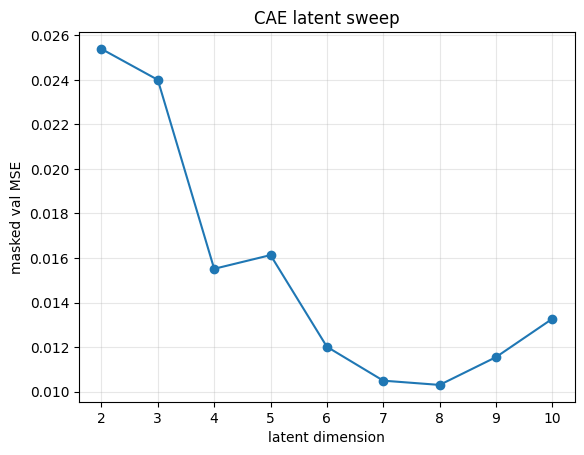

In [ ]:
# Convolutional autoencoder: convolves along time across the 20 intervals
# Same masked_mse loss and same (N, T, C) data as the dense AE, but the encoder now slides 1D filters over the time axis, so it captures local temporal patterns
# (across neighbouring intervals) rather than treating each interval independently.

class ConvAE(nn.Module):
    def __init__(self, C, latent, T):
        super().__init__()
        # encoder: 1D convs along time. Input shape (batch, C=channels, T=number of time steps)
        self.enc = nn.Sequential(
            nn.Conv1d(C, 16, kernel_size=3, padding=1), nn.ReLU(),   # local time patterns (603 patients, 16 feature maps, 20 time intervals)
            nn.Conv1d(16, latent, kernel_size=3, padding=1)          # -> latent per time-step (603 patients, 11 latent features, 20 time intervals)
        )
        # decoder: mirror with transpose convs to reconstruct the C channels
        self.dec = nn.Sequential(
            nn.ConvTranspose1d(latent, 16, kernel_size=3, padding=1), nn.ReLU(),
            nn.ConvTranspose1d(16, C, kernel_size=3, padding=1)
        )
    def forward(self, x):
        # x comes in as (batch, T, C); conv1d wants (batch, C, T)
        x = x.transpose(1, 2)
        z = self.enc(x)                 # (batch, latent, T)
        recon = self.dec(z)             # (batch, C, T)
        # transpose back to (batch, T, C) so it matches the input / mask layout
        return recon.transpose(1, 2), z.transpose(1, 2)

# train the conv AE on WHOLE patient windows (not flattened), with masked reconstruction
def train_conv_ae(latent, epochs=120, lr=1e-3, batch=64, seed=42):
    torch.manual_seed(seed)
    Xtr, Mtr = to_t(Xn[tr]), to_t(M[tr])            # (N_tr, T, C) — keep the time axis
    Xva, Mva = to_t(Xn[va]), to_t(M[va])

    model = ConvAE(C, latent, T); opt = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(epochs):
        model.train()
        for b in torch.randperm(len(Xtr)).split(batch):
            opt.zero_grad()
            recon, _ = model(Xtr[b]); loss = masked_mse(recon, Xtr[b], Mtr[b])
            loss.backward(); opt.step()

    model.eval()
    with torch.no_grad():
        vl = masked_mse(model(Xva)[0], Xva, Mva).item()
    return model, vl

# sweep latent size
conv_ae = {}
for latent in LATENT_SWEEP:
    model, vl = train_conv_ae(latent)
    conv_ae[latent] = {"model": model, "val": vl}
    print(f"conv latent {latent}: masked val MSE {vl:.5f}")

plt.plot(list(conv_ae), [conv_ae[k]["val"] for k in conv_ae], "o-")
plt.xlabel("latent dimension"); plt.ylabel("masked val MSE"); plt.title("CAE latent sweep")
plt.grid(alpha=.3); plt.show()

conv latent 2: masked val MSE 0.02719 +/- 0.00290
conv latent 3: masked val MSE 0.02256 +/- 0.00163
conv latent 4: masked val MSE 0.01947 +/- 0.00282
conv latent 5: masked val MSE 0.01740 +/- 0.00185
conv latent 6: masked val MSE 0.01402 +/- 0.00161
conv latent 7: masked val MSE 0.01355 +/- 0.00247
conv latent 8: masked val MSE 0.01145 +/- 0.00148
conv latent 9: masked val MSE 0.01127 +/- 0.00207
conv latent 10: masked val MSE 0.00987 +/- 0.00082


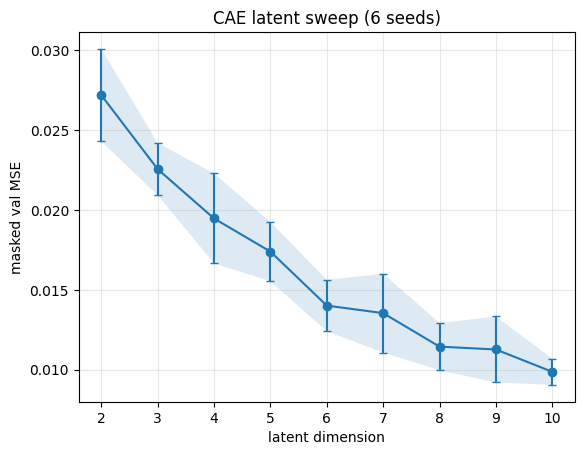

In [ ]:
SWEEP_SEEDS = range(6)

conv_ae = {}
for k in LATENT_SWEEP:
    vals, models = [], []
    for s in SWEEP_SEEDS:
        m, vl = train_conv_ae(k, seed=s)
        vals.append(vl); models.append(m)
    vals = np.array(vals)
    # keep the median-performing seed's model, not the luckiest one
    keep = int(np.argsort(vals)[len(vals) // 2])
    conv_ae[k] = {"model": models[keep], "val": vals.mean(),
                  "std": vals.std(), "all": vals}
    print(f"conv latent {k}: masked val MSE {vals.mean():.5f} +/- {vals.std():.5f}")

ks   = list(conv_ae)
mean = np.array([conv_ae[k]["val"] for k in ks])
sd   = np.array([conv_ae[k]["std"] for k in ks])

plt.errorbar(ks, mean, yerr=sd, fmt="o-", capsize=3)
plt.fill_between(ks, mean - sd, mean + sd, alpha=.15)
plt.xlabel("latent dimension"); plt.ylabel("masked val MSE")
plt.title(f"CAE latent sweep ({len(SWEEP_SEEDS)} seeds)")
plt.grid(alpha=.3); plt.show()

In [ ]:
CONV_LATENT = 9
conv_encoder = conv_ae[CONV_LATENT]["model"]
conv_encoder.eval()

with torch.no_grad():
    # feed WHOLE windows (N, T, C) -> conv encoder -> latent sequence (N, T, latent)
    _, Zseq_conv = conv_encoder(to_t(Xn))
    Zseq_conv = Zseq_conv.numpy()

print("conv latent sequence:", Zseq_conv.shape)   # (N, T, CONV_LATENT)

conv latent sequence: (603, 20, 9)


In [ ]:
# the three input representations for the ablation
Mseq = M                                   # (N, T, C) per-interval presence pattern
inputs = {
    "latents only (physiology)": Zseq_conv,                                  # (N, T, latent)
    "presence (mask) only":      Mseq,                                  # (N, T, C)
    "latents + mask":            np.concatenate([Zseq_conv, Mseq], axis=2),  # (N, T, latent+C)
}


# train and evaluate one model; returns AUROC on the chosen evaluation split (validation or test)
def train_eval_lstm(Xin, y, seed, hidden=32, eval_split="test", epochs=200, lr=1e-3):
    torch.manual_seed(seed)
    # filter patients to those with a non-missing label
    keep = lambda s: np.array([i for i in s if not np.isnan(y[i])])
    trL = keep(tr)
    evalL = keep(va) if eval_split == "val" else keep(te)   # evaluate on validation or test
    # convert features to a tensor
    Xt = to_t(Xin); yt = to_t(np.nan_to_num(y).reshape(-1, 1))

    # create the model with input dimension Xin.shape[2], chosen hidden size, Adam optimizer and lossf (binary cross-entropy loss)
    model = LSTMClassifier(Xin.shape[2], hidden=hidden); opt = torch.optim.Adam(model.parameters(), lr=lr)
    lossf = nn.BCEWithLogitsLoss()
    for _ in range(epochs):
        model.train(); opt.zero_grad()
        loss = lossf(model(Xt[trL]), yt[trL]); loss.backward(); opt.step()
    model.eval()
    with torch.no_grad():
        p = model(Xt[evalL]).numpy().ravel()
    return roc_auc_score(y[evalL], p)

ENCODER = "conv"

SEEDS = range(6)
HIDDEN_SIZES = [16, 32, 64]                 # candidate LSTM memory sizes
for task in ["mortality", "transfusion"]:
    y = make_target(task)
    n_pos = int(np.nansum(y)); n_lab = int((~np.isnan(y)).sum())
    print(f"\n===== {task}  (positives {n_pos} of {n_lab} labelled) =====")
    # for each of the ablation inputs, choose the hidden size on the VALIDATION set, then report on TEST
    for name, Xin in inputs.items():
        # average validation AUROC across seeds for each candidate hidden size
        val_scores = {}
        for hidden in HIDDEN_SIZES:
            val_aucs = np.array([train_eval_lstm(Xin, y, s, hidden=hidden, eval_split="val") for s in SEEDS])
            val_scores[hidden] = val_aucs.mean()
        # pick the hidden size with the best validation AUROC
        best_hidden = max(val_scores, key=val_scores.get)
        # report the TEST AUROC for the chosen hidden size (averaged across seeds)
        test_aucs = np.array([train_eval_lstm(Xin, y, s, hidden=best_hidden, eval_split="test") for s in SEEDS])
        tuning[(ENCODER, task, name)] = {"hidden": best_hidden,
                                         "val": val_scores[best_hidden],
                                         "test": test_aucs}
        print(f"  {name:26s}: best hidden={best_hidden:>2} (val {val_scores[best_hidden]:.3f}) "
              f"| test AUROC {test_aucs.mean():.3f} ± {test_aucs.std():.3f}")


===== mortality  (positives 90 of 559 labelled) =====
  latents only (physiology) : best hidden=64 (val 0.631) | test AUROC 0.771 ± 0.032
  presence (mask) only      : best hidden=64 (val 0.649) | test AUROC 0.718 ± 0.024
  latents + mask            : best hidden=64 (val 0.620) | test AUROC 0.735 ± 0.030

===== transfusion  (positives 108 of 602 labelled) =====
  latents only (physiology) : best hidden=32 (val 0.561) | test AUROC 0.661 ± 0.032
  presence (mask) only      : best hidden=16 (val 0.558) | test AUROC 0.662 ± 0.018
  latents + mask            : best hidden=16 (val 0.556) | test AUROC 0.670 ± 0.032


[conv] mortality | hidden=64 (validation-selected)
  Brier (model):    0.134 +/- 0.010  over 6 seeds
  Brier (baseline): 0.147  (always predict base rate 0.18)
  => model is better than baseline

bin  mean_predicted_risk  actual_death_rate
     0.03                 0.00
     0.05                 0.12
     0.09                 0.12
     0.14                 0.18
     0.41                 0.47


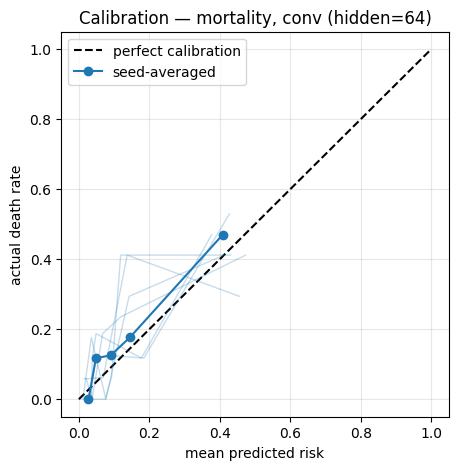

[conv] transfusion | hidden=32 (validation-selected)
  Brier (model):    0.161 +/- 0.005  over 6 seeds
  Brier (baseline): 0.159  (always predict base rate 0.20)
  => model is NOT better than baseline

bin  mean_predicted_risk  actual_death_rate
     0.06                 0.00
     0.10                 0.22
     0.20                 0.36
     0.36                 0.22


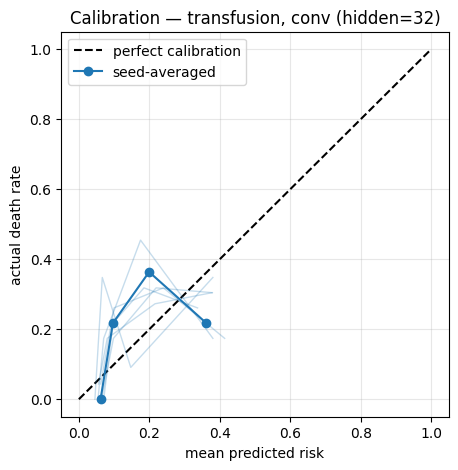

In [ ]:
cal_conv_mort  = calibrate("conv", Zseq_conv, task="mortality")
cal_conv_trans = calibrate("conv", Zseq_conv, task="transfusion", n_bins=4)


## 3. Raw channels + LSTM

In [ ]:
# RAW CHANNELS + LSTM (no autoencoder)
# Feed the normalised raw vitals straight into the same LSTM, with the same
# validation-selected hidden-size sweep and three-way ablation, for comparison against the autoencoder pipelines.

raw_inputs = {
    "raw channels (physiology)": Xn,                                   # (N, T, C)
    "presence (mask) only":      M,                                    # (N, T, C)
    "raw + mask":                np.concatenate([Xn, M], axis=2),      # (N, T, 2C)
}

ENCODER = "raw"

for task in ["mortality", "transfusion"]:
    y = make_target(task)
    n_pos = int(np.nansum(y)); n_lab = int((~np.isnan(y)).sum())
    print(f"\n===== {task}  (positives {n_pos} of {n_lab} labelled) =====")
    for name, Xin in raw_inputs.items():
        # choose hidden size on VALIDATION, then report on TEST
        val_scores = {}
        for hidden in HIDDEN_SIZES:
            val_aucs = np.array([train_eval_lstm(Xin, y, s, hidden=hidden, eval_split="val") for s in SEEDS])
            val_scores[hidden] = val_aucs.mean()
        best_hidden = max(val_scores, key=val_scores.get)
        test_aucs = np.array([train_eval_lstm(Xin, y, s, hidden=best_hidden, eval_split="test") for s in SEEDS])
        tuning[(ENCODER, task, name)] = {"hidden": best_hidden,
                                         "val": val_scores[best_hidden],
                                         "test": test_aucs}
        print(f"  {name:26s}: best hidden={best_hidden:>2} (val {val_scores[best_hidden]:.3f}) "
              f"| test AUROC {test_aucs.mean():.3f} ± {test_aucs.std():.3f}")


===== mortality  (positives 90 of 559 labelled) =====
  raw channels (physiology) : best hidden=16 (val 0.662) | test AUROC 0.857 ± 0.026
  presence (mask) only      : best hidden=64 (val 0.649) | test AUROC 0.718 ± 0.024
  raw + mask                : best hidden=32 (val 0.633) | test AUROC 0.784 ± 0.019

===== transfusion  (positives 108 of 602 labelled) =====
  raw channels (physiology) : best hidden=16 (val 0.590) | test AUROC 0.674 ± 0.014
  presence (mask) only      : best hidden=16 (val 0.558) | test AUROC 0.662 ± 0.018
  raw + mask                : best hidden=16 (val 0.548) | test AUROC 0.656 ± 0.016


[raw] mortality | hidden=16 (validation-selected)
  Brier (model):    0.119 +/- 0.005  over 6 seeds
  Brier (baseline): 0.147  (always predict base rate 0.18)
  => model is better than baseline

bin  mean_predicted_risk  actual_death_rate
     0.06                 0.00
     0.07                 0.00
     0.12                 0.00
     0.20                 0.35
     0.30                 0.53


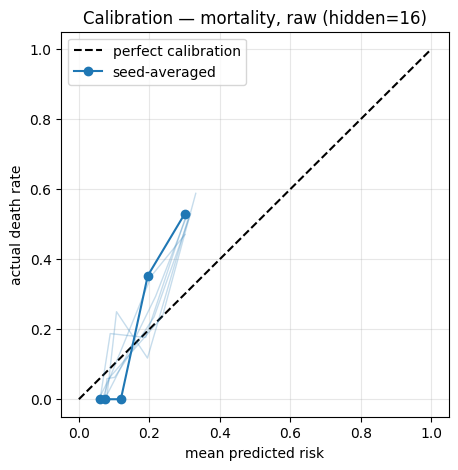

[raw] transfusion | hidden=16 (validation-selected)
  Brier (model):    0.152 +/- 0.002  over 6 seeds
  Brier (baseline): 0.159  (always predict base rate 0.20)
  => model is better than baseline

bin  mean_predicted_risk  actual_death_rate
     0.08                 0.04
     0.11                 0.22
     0.19                 0.23
     0.32                 0.30


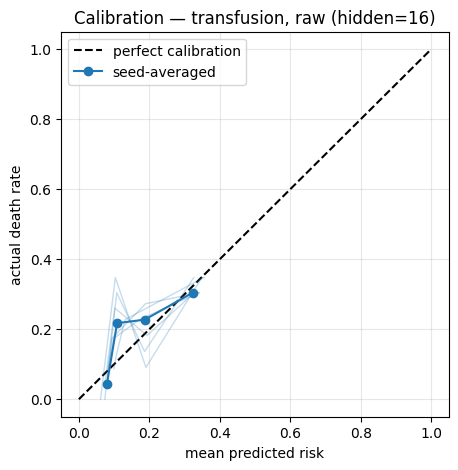

In [ ]:
RAW_NAME = "raw channels (physiology)"
cal_raw_mort  = calibrate("raw", Xn, task="mortality",   name=RAW_NAME)
cal_raw_trans = calibrate("raw", Xn, task="transfusion", name=RAW_NAME, n_bins=4)


## 4. Combined ROC comparison


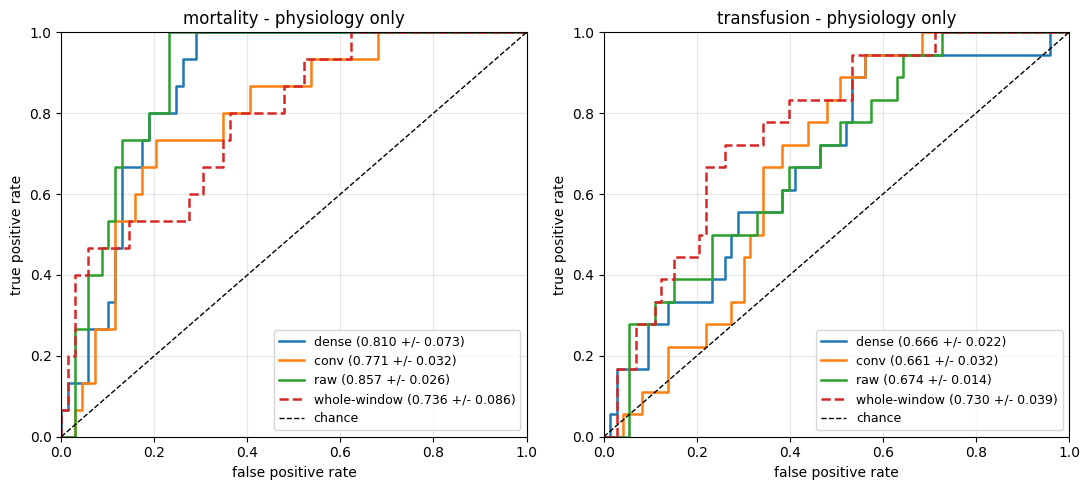

In [ ]:
# combined ROC curves
# One panel per task, one curve per encoder. Curves are built from
# seed-averaged test probabilities; the legend reports the multi-seed test
# AUROC (mean +/- sd) exactly as in the results table.
from sklearn.metrics import roc_curve

RAW_NAME = "raw channels (physiology)"
PHYS     = "latents only (physiology)"
WW_FILE = "ww_test_probs.npz"


def seed_avg_probs(encoder, Xin, task, name):
    """Seed-averaged test probabilities at the validation-selected width."""
    h = tuning[(encoder, task, name)]["hidden"]
    y = make_target(task)
    runs = [lstm_test_probs(Xin, y, s, h) for s in SEEDS]
    return np.mean([p for p, _ in runs], axis=0), runs[0][1]


def auroc_label(encoder, task, name):
    a = tuning[(encoder, task, name)]["test"]
    return f"{encoder} ({a.mean():.3f} +/- {a.std():.3f})"


def task_test_ids(task):
    """Patient ids of this notebook's labelled test set for a given task."""
    y = make_target(task)
    teL = np.array([i for i in te if not np.isnan(y[i])])
    return np.asarray(ids, dtype=str)[teL]


SPECS = [("dense", "Zseq_dense", PHYS),
         ("conv",  "Zseq_conv",  PHYS),
         ("raw",   "Xn",         RAW_NAME)]

try:
    ww = np.load(WW_FILE)
except FileNotFoundError:
    ww = None
    print(f"note: {WW_FILE} not found - plotting the three sequence encoders only\n")

TASKS = ["mortality", "transfusion"]
fig, axes = plt.subplots(1, len(TASKS), figsize=(11, 5))

for ax, task in zip(np.atleast_1d(axes), TASKS):
    for encoder, arr_name, name in SPECS:
        Xin = globals()[arr_name]
        p, y_true = seed_avg_probs(encoder, Xin, task, name)
        fpr, tpr, _ = roc_curve(y_true, p)
        ax.plot(fpr, tpr, linewidth=1.8, label=auroc_label(encoder, task, name))

    if ww is not None and f"{task}_ids" in ww:
        # only plot the whole-window curve if both notebooks selected the same
        # test patients; otherwise the curve sits on a different denominator
        local = task_test_ids(task)
        wid   = ww[f"{task}_ids"].astype(str)
        if set(wid) != set(local):
            shared = len(set(wid) & set(local))
            print(f"  {task}: skipping whole-window - test sets differ "
                  f"({shared} of {len(local)} patients shared)")
        else:
            order = {k: j for j, k in enumerate(wid)}
            sel   = np.array([order[k] for k in local])
            p_ww, y_ww = ww[f"{task}_p"][sel], ww[f"{task}_y"][sel]
            fpr, tpr, _ = roc_curve(y_ww, p_ww)
            a = ww[f"{task}_aucs"]
            ax.plot(fpr, tpr, linewidth=1.8, linestyle="--",
                    label=f"whole-window ({a.mean():.3f} +/- {a.std():.3f})")

    ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="chance")
    ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
    ax.set_title(f"{task} - physiology only")
    ax.legend(loc="lower right", fontsize=9); ax.grid(alpha=.3)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)

plt.tight_layout(); plt.show()
